# Supervised Machine Learning Classification Project
## Breast Cancer Wisconsin (Original) — Benign vs. Malignant Tumor Classification

**Objective:** Build and compare five supervised classifiers (KNN, Decision Tree, Random Forest, ANN, SVM) to predict whether a breast tumor is **benign** or **malignant** from cell-nucleus measurements, and select the best model using experimental results.

**Key design decisions (followed throughout the notebook):**
- Malignant is the **positive class** (`1`); benign is `0`.
- The data is split **80:20 (stratified)** *before* any statistic is learned from it.
- Imputation and scaling are placed inside a scikit-learn `Pipeline`, so they are fitted **only on training folds** → no data leakage.
- Hyperparameters are tuned with `GridSearchCV` (5-fold stratified CV) on the **training set only**. The test set is used **once**, at the very end.

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

# Folder where every figure is saved (handy for the presentation slides)
os.makedirs("figures", exist_ok=True)
def save_fig(name):
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

---
# Task 1: Dataset Exploration

### 1.1 Load the dataset

The original dataset has **no header row**, so column names are supplied manually based on the UCI documentation.
Missing values are written as `?` in the raw file. We first load it **as-is** to inspect that issue.

> The code reads `breast-cancer-wisconsin.data` from the notebook folder if it exists; otherwise it downloads it from UCI.

In [3]:
COLS = ["Sample_code_number", "Clump_Thickness", "Uniformity_of_Cell_Size",
        "Uniformity_of_Cell_Shape", "Marginal_Adhesion", "Single_Epithelial_Cell_Size",
        "Bare_Nuclei", "Bland_Chromatin", "Normal_Nucleoli", "Mitoses", "Class"]

URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
       "breast-cancer-wisconsin/breast-cancer-wisconsin.data")
LOCAL = "breast-cancer-wisconsin.data"

source = LOCAL if os.path.exists(LOCAL) else URL
print("Loading from:", source)
raw = pd.read_csv(source, header=None, names=COLS)   # '?' kept as text for now
raw.head()

Loading from: https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


### 1.2 Structure, dimensions, column names and data types

In [4]:
print("Shape (rows, columns):", raw.shape)
print("\nColumn names:", list(raw.columns))
print()
raw.info()

Shape (rows, columns): (699, 11)

Column names: ['Sample_code_number', 'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class']

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Sample_code_number           699 non-null    int64
 1   Clump_Thickness              699 non-null    int64
 2   Uniformity_of_Cell_Size      699 non-null    int64
 3   Uniformity_of_Cell_Shape     699 non-null    int64
 4   Marginal_Adhesion            699 non-null    int64
 5   Single_Epithelial_Cell_Size  699 non-null    int64
 6   Bare_Nuclei                  699 non-null    str  
 7   Bland_Chromatin              699 non-null    int64
 8   Normal_Nucleoli              699 non-null    int64
 9   Mitoses       

**Observation:** `Bare_Nuclei` has dtype `object` while all other columns are integers. This is because the raw file uses the character `?` for missing values. We convert `?` to `NaN` and cast the column to numeric.

In [5]:
print("Number of '?' entries per column:")
print((raw == "?").sum())

df = raw.replace("?", np.nan)
df["Bare_Nuclei"] = pd.to_numeric(df["Bare_Nuclei"])
print("\nDtypes after conversion:")
print(df.dtypes)

Number of '?' entries per column:
Sample_code_number              0
Clump_Thickness                 0
Uniformity_of_Cell_Size         0
Uniformity_of_Cell_Shape        0
Marginal_Adhesion               0
Single_Epithelial_Cell_Size     0
Bare_Nuclei                    16
Bland_Chromatin                 0
Normal_Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64

Dtypes after conversion:
Sample_code_number               int64
Clump_Thickness                  int64
Uniformity_of_Cell_Size          int64
Uniformity_of_Cell_Shape         int64
Marginal_Adhesion                int64
Single_Epithelial_Cell_Size      int64
Bare_Nuclei                    float64
Bland_Chromatin                  int64
Normal_Nucleoli                  int64
Mitoses                          int64
Class                            int64
dtype: object


### 1.3 Target variable, features and feature meanings (from the UCI documentation)

| Column | Meaning | Range |
|---|---|---|
| `Sample_code_number` | Unique patient/sample ID — **not a feature** | — |
| `Clump_Thickness` | Thickness of cell clumps (malignant cells tend to group in multilayers) | 1–10 |
| `Uniformity_of_Cell_Size` | Consistency of cell size | 1–10 |
| `Uniformity_of_Cell_Shape` | Consistency of cell shape | 1–10 |
| `Marginal_Adhesion` | How much cells stick together at the margins | 1–10 |
| `Single_Epithelial_Cell_Size` | Size of single epithelial cells | 1–10 |
| `Bare_Nuclei` | Nuclei not surrounded by cytoplasm | 1–10 |
| `Bland_Chromatin` | Texture of the nucleus chromatin | 1–10 |
| `Normal_Nucleoli` | Size/visibility of nucleoli | 1–10 |
| `Mitoses` | Rate of cell division | 1–10 |
| **`Class`** | **Target:** `2` = benign, `4` = malignant | 2 / 4 |

- **Target variable:** `Class` (will be recoded to `0` = benign, `1` = malignant, so malignant is the positive class).
- **Predictive features:** the 9 cytological measurements (all ordinal scores from 1 to 10).

### 1.4 Descriptive statistics

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Sample_code_number,699.0,1071704.10,617095.73,61634.0,870688.5,1171710.0,1238298.0,13454352.0
Clump_Thickness,699.0,4.42,2.82,1.0,2.0,4.0,6.0,10.0
Uniformity_of_Cell_Size,699.0,3.13,3.05,1.0,1.0,1.0,5.0,10.0
Uniformity_of_Cell_Shape,699.0,3.21,2.97,1.0,1.0,1.0,5.0,10.0
Marginal_Adhesion,699.0,2.81,2.86,1.0,1.0,1.0,4.0,10.0
Single_Epithelial_Cell_Size,699.0,3.22,2.21,1.0,2.0,2.0,4.0,10.0
Bare_Nuclei,683.0,3.54,3.64,1.0,1.0,1.0,6.0,10.0
Bland_Chromatin,699.0,3.44,2.44,1.0,2.0,3.0,5.0,10.0
Normal_Nucleoli,699.0,2.87,3.05,1.0,1.0,1.0,4.0,10.0
Mitoses,699.0,1.59,1.72,1.0,1.0,1.0,1.0,10.0


### 1.5 Missing values

In [7]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"Missing count": missing, "Missing %": missing_pct})

,Missing count,Missing %
Sample_code_number,0,0.00
Clump_Thickness,0,0.00
Uniformity_of_Cell_Size,0,0.00
Uniformity_of_Cell_Shape,0,0.00
Marginal_Adhesion,0,0.00
Single_Epithelial_Cell_Size,0,0.00
Bare_Nuclei,16,2.29
Bland_Chromatin,0,0.00
Normal_Nucleoli,0,0.00
Mitoses,0,0.00


### 1.6 Duplicate records

In [8]:
print("Fully duplicated rows (including ID)          :", df.duplicated().sum())
print("Duplicated Sample_code_number (repeated IDs)  :", df["Sample_code_number"].duplicated().sum())
print("Duplicated rows after removing the ID column  :", df.drop(columns="Sample_code_number").duplicated().sum())

Fully duplicated rows (including ID)          : 8
Duplicated Sample_code_number (repeated IDs)  : 54
Duplicated rows after removing the ID column  : 236


**Observation:** Some `Sample_code_number` values repeat (the same patient was sampled more than once, in different groups/dates), and some rows are identical in all measurements and label once the ID is ignored. Because the ID is not a feature, identical measurement rows carry no new information; if they were split across train and test they would also **inflate test performance**. We therefore remove them in Task 2.

### 1.7 Class distribution

In [9]:
counts = df["Class"].value_counts().sort_index()
pct = (counts / len(df) * 100).round(2)
pd.DataFrame({"Count": counts.values, "Percent": pct.values}, index=["2 (Benign)", "4 (Malignant)"])

,Count,Percent
2 (Benign),458,65.52
4 (Malignant),241,34.48


**Observation:** The classes are moderately imbalanced (roughly 65% benign / 35% malignant). This is why we use a **stratified** split and look at Precision/Recall/F1/ROC-AUC rather than accuracy alone.

---
# Task 2: Data Preprocessing

Steps, in order:
1. Remove the irrelevant identifier column.
2. Remove duplicate records.
3. Encode the target: benign → `0`, malignant → `1`.
4. **Stratified 80:20 train/test split.**
5. Handle missing values (median imputation) and standardize — both **fitted on training data only**.

Removing the ID and duplicates, and re-coding the label, learn nothing from the data distribution, so doing them before the split is leakage-free. Imputation and scaling *do* learn statistics (median, mean, std), so they come **after** the split.

In [10]:
# 1) Remove TRUE duplicate records (identical ID + measurements + label)
n_before = len(df)
df_nodup = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n_before} | after removing exact duplicates: {len(df_nodup)} | removed: {n_before - len(df_nodup)}")

# 2) Drop the identifier
data = df_nodup.drop(columns="Sample_code_number")

# 3) Encode the target: malignant (4) -> 1 = POSITIVE class, benign (2) -> 0
data["Class"] = data["Class"].map({2: 0, 4: 1})

X = data.drop(columns="Class")
y = data["Class"]
print("\nClass balance after cleaning:\n", y.value_counts(normalize=True).round(3))

Rows before: 699 | after removing exact duplicates: 691 | removed: 8

Class balance after cleaning:
 Class
0    0.656
1    0.344
Name: proportion, dtype: float64


In [11]:
# 4) Stratified 80:20 split (done BEFORE imputation / scaling)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nMalignant share  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))
print("Missing values in train:", int(X_train.isnull().sum().sum()),
      "| in test:", int(X_test.isnull().sum().sum()))

Train: (552, 9) | Test: (139, 9)

Malignant share  train: 0.344 | test: 0.345
Missing values in train: 14 | in test: 2


### Handling missing values
Only `Bare_Nuclei` has missing values (a small percentage). Dropping those rows would waste data, so we use **median imputation**. The median is appropriate because the feature is an ordinal 1–10 score that is right-skewed, and it is robust to outliers. The median is **learned from the training set only** and then applied to both train and test. Inside the model pipelines this is done by `SimpleImputer(strategy="median")`, so during cross-validation it is re-fitted on each training fold.

### Standardization
`StandardScaler` (z-score) is required by distance/gradient-based models: **KNN, SVM and ANN**. Tree-based models (Decision Tree, Random Forest) are scale-invariant, so they get the imputer only. For the *visualization* of standardization below, we fit the imputer and scaler on `X_train` only.

In [12]:
# Fit on TRAIN only, then transform train and test (used for visualizations / sanity checks)
imputer_vis = SimpleImputer(strategy="median").fit(X_train)
X_train_imp = pd.DataFrame(imputer_vis.transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp  = pd.DataFrame(imputer_vis.transform(X_test),  columns=X.columns, index=X_test.index)

scaler_vis = StandardScaler().fit(X_train_imp)
X_train_scaled = pd.DataFrame(scaler_vis.transform(X_train_imp), columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler_vis.transform(X_test_imp),  columns=X.columns, index=X_test.index)

print("Imputation median used for Bare_Nuclei (from train):", imputer_vis.statistics_[list(X.columns).index("Bare_Nuclei")])
print("\nScaled TRAIN  -> mean ~0, std ~1:")
print(X_train_scaled.describe().loc[["mean", "std"]].round(3))
print("\nScaled TEST   -> close to, but not exactly, 0/1 (expected: scaler learned from train only):")
print(X_test_scaled.describe().loc[["mean", "std"]].round(3))

Imputation median used for Bare_Nuclei (from train): 1.0

Scaled TRAIN  -> mean ~0, std ~1:
      Clump_Thickness  Uniformity_of_Cell_Size  Uniformity_of_Cell_Shape  \
mean           -0.000                    0.000                    -0.000   
std             1.001                    1.001                     1.001   

      Marginal_Adhesion  Single_Epithelial_Cell_Size  Bare_Nuclei  \
mean              0.000                       -0.000        0.000   
std               1.001                        1.001        1.001   

      Bland_Chromatin  Normal_Nucleoli  Mitoses  
mean           -0.000            0.000    0.000  
std             1.001            1.001    1.001  

Scaled TEST   -> close to, but not exactly, 0/1 (expected: scaler learned from train only):
      Clump_Thickness  Uniformity_of_Cell_Size  Uniformity_of_Cell_Shape  \
mean           -0.062                   -0.018                    -0.039   
std             1.036                    0.983                     0.988   


---
# Task 3: Exploratory Data Analysis (EDA)

To respect the "keep the test set separate" rule, EDA is performed on the **training set** (except the missing-value chart, which is a data-quality check on the raw data).

### 3.1 Missing values (counts and percentages)

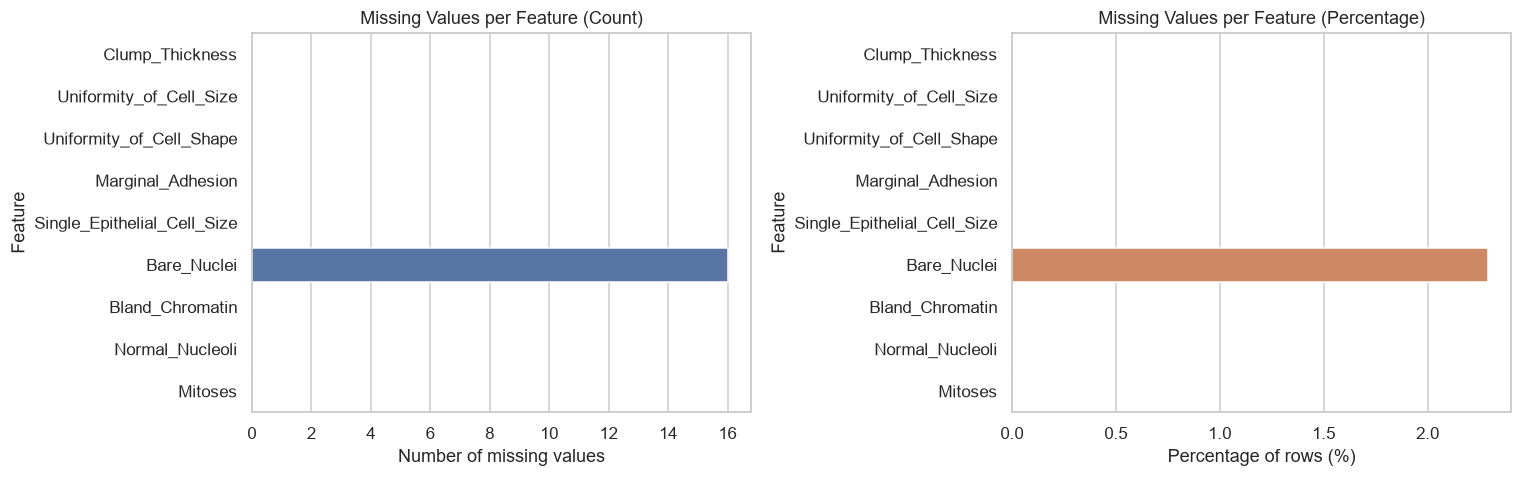

In [13]:
mv = df.drop(columns=["Sample_code_number", "Class"]).isnull().sum()
mv_pct = mv / len(df) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=mv.values, y=mv.index, ax=axes[0], color="#4C72B0")
axes[0].set_title("Missing Values per Feature (Count)")
axes[0].set_xlabel("Number of missing values"); axes[0].set_ylabel("Feature")

sns.barplot(x=mv_pct.values, y=mv_pct.index, ax=axes[1], color="#DD8452")
axes[1].set_title("Missing Values per Feature (Percentage)")
axes[1].set_xlabel("Percentage of rows (%)"); axes[1].set_ylabel("Feature")
plt.tight_layout(); save_fig("01_missing_values"); plt.show()

**Interpretation:** Only `Bare_Nuclei` contains missing values (about 2% of the rows); all other features are complete. Since the amount is small and confined to one feature, median imputation is a safe and simple strategy.

### 3.2 Target class distribution (count plot)

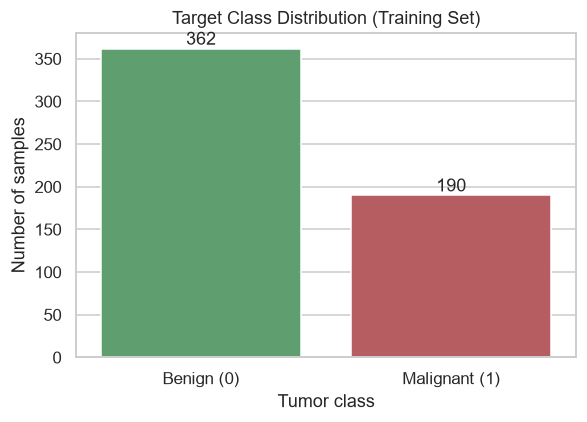

In [14]:
plt.figure(figsize=(5.5, 4))
ax = sns.countplot(x=y_train.map({0: "Benign (0)", 1: "Malignant (1)"}),
                   order=["Benign (0)", "Malignant (1)"], palette=["#55A868", "#C44E52"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Target Class Distribution (Training Set)")
plt.xlabel("Tumor class"); plt.ylabel("Number of samples")
plt.tight_layout(); save_fig("02_class_distribution"); plt.show()

**Interpretation:** Benign cases are the majority (~65%) and malignant ~35%. The imbalance is moderate, not extreme, but it justifies stratified splitting/CV and reporting Recall, F1 and ROC-AUC besides accuracy.

### 3.3 Feature distributions (histograms)

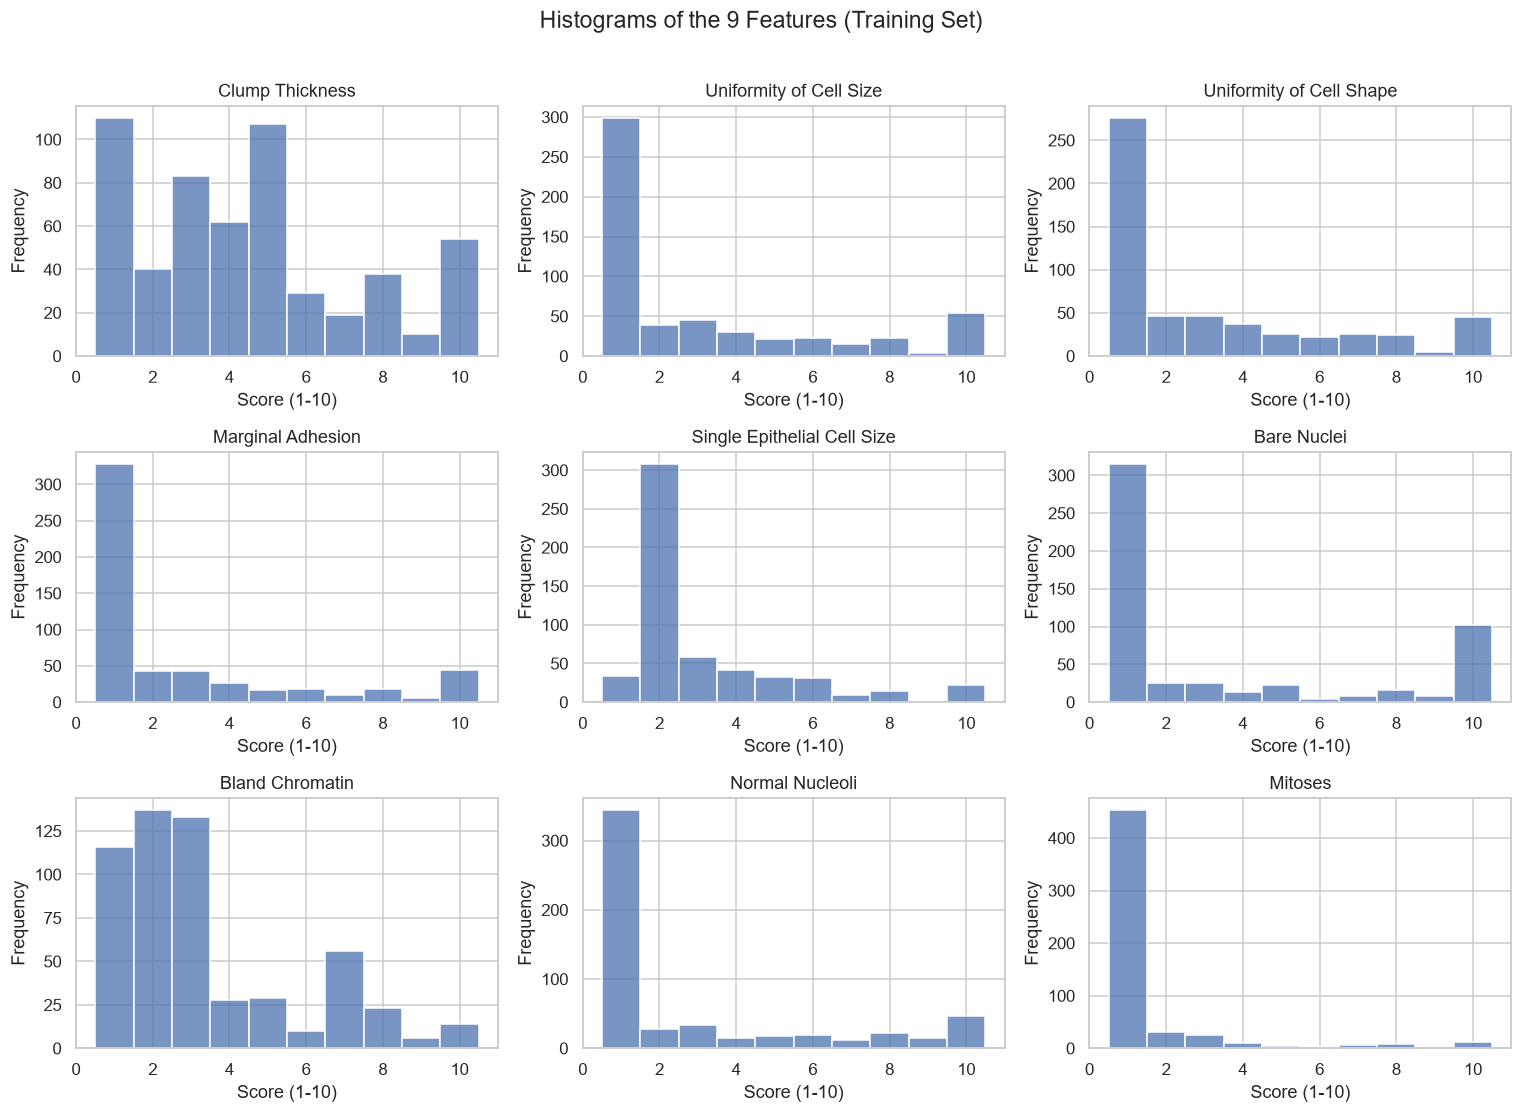

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), X_train.columns):
    sns.histplot(X_train[col], bins=10, discrete=True, color="#4C72B0", ax=ax)
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("Score (1-10)"); ax.set_ylabel("Frequency")
fig.suptitle("Histograms of the 9 Features (Training Set)", fontsize=15, y=1.01)
plt.tight_layout(); save_fig("03_histograms"); plt.show()

**Interpretation:** Most features are strongly **right-skewed**: the majority of samples have low scores (1–3), with a long tail towards 10. `Mitoses` is the most extreme (almost all values equal 1). `Clump_Thickness` and `Bland_Chromatin` are more spread out. The ordinal 1–10 scale and skewness mean we should avoid assuming normality.

### 3.4 Boxplots by class (comparison and outliers)

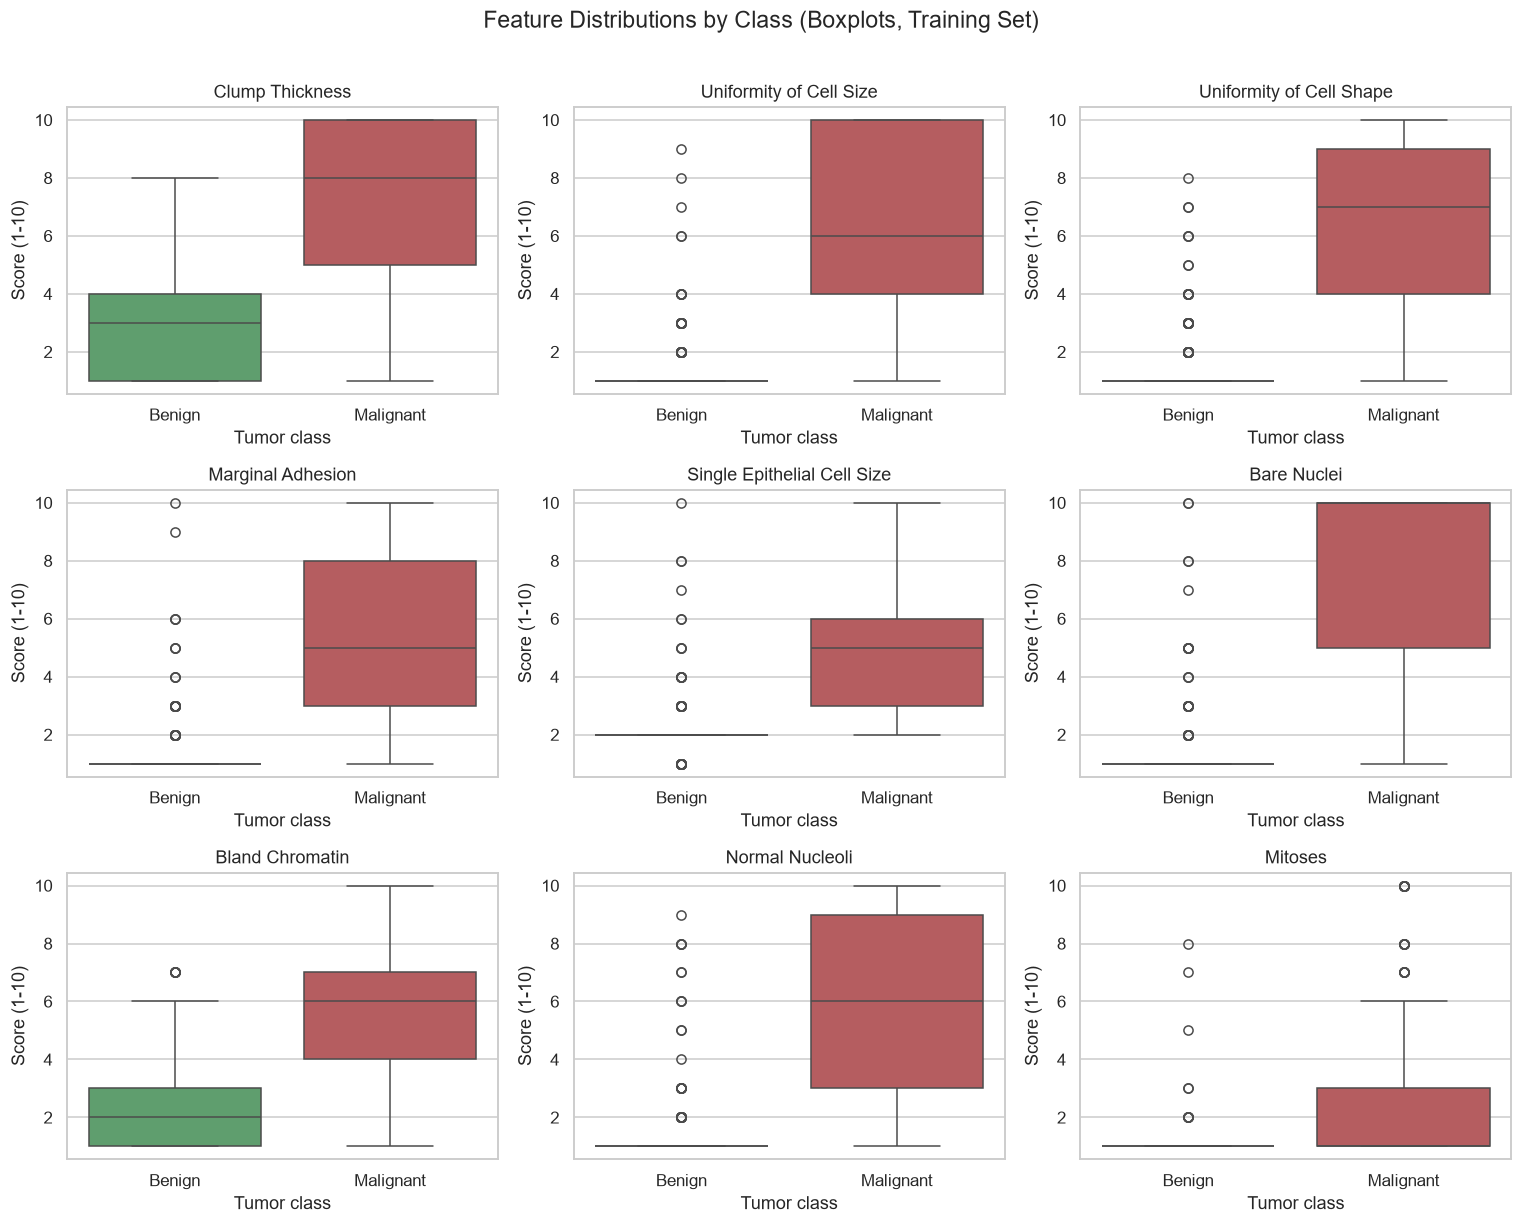

In [16]:
plot_df = X_train.copy()
plot_df["Class"] = y_train.map({0: "Benign", 1: "Malignant"})

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, col in zip(axes.ravel(), X_train.columns):
    sns.boxplot(data=plot_df, x="Class", y=col, order=["Benign", "Malignant"],
                palette=["#55A868", "#C44E52"], ax=ax)
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("Tumor class"); ax.set_ylabel("Score (1-10)")
fig.suptitle("Feature Distributions by Class (Boxplots, Training Set)", fontsize=15, y=1.01)
plt.tight_layout(); save_fig("04_boxplots_by_class"); plt.show()

**Interpretation:** For almost every feature the malignant group sits **much higher** than the benign group, which means the features are strongly discriminative. Benign samples are tightly concentrated at low values with several outlier points above the whiskers; `Mitoses` shows the weakest separation. The outliers are valid clinical scores (not data errors), so they are **kept**.

### 3.5 Correlation heatmap

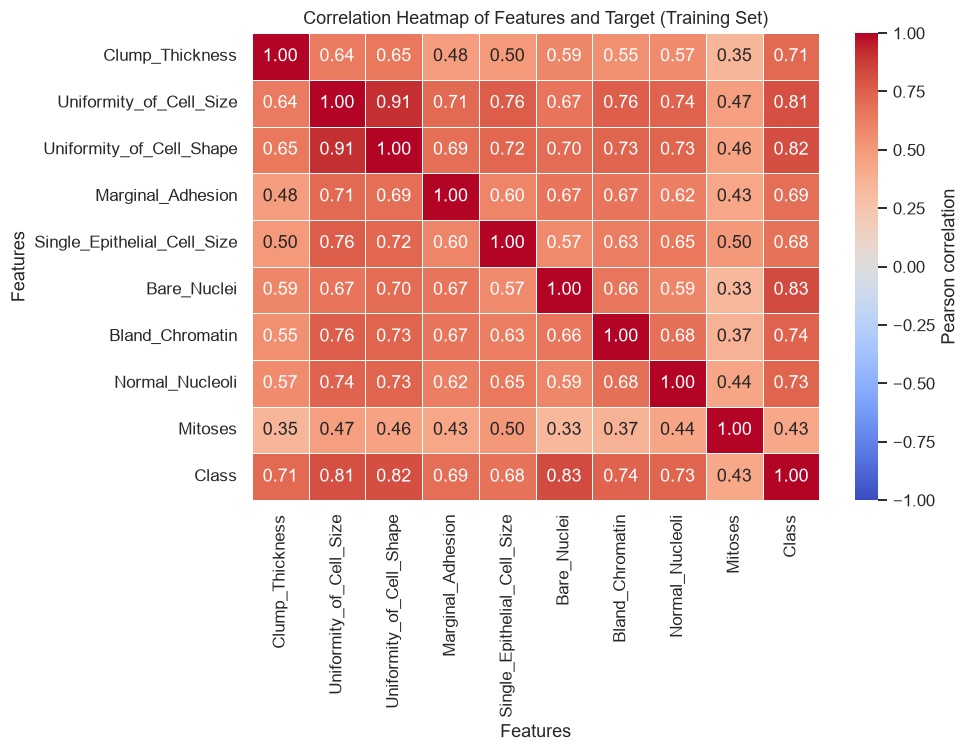

Correlation of each feature with the target (sorted):
Bare_Nuclei                    0.826
Uniformity_of_Cell_Shape       0.815
Uniformity_of_Cell_Size        0.810
Bland_Chromatin                0.741
Normal_Nucleoli                0.729
Clump_Thickness                0.714
Marginal_Adhesion              0.692
Single_Epithelial_Cell_Size    0.678
Mitoses                        0.428
Name: Class, dtype: float64


In [17]:
corr = X_train.assign(Class=y_train).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Features and Target (Training Set)")
plt.xlabel("Features"); plt.ylabel("Features")
plt.tight_layout(); save_fig("05_correlation_heatmap"); plt.show()

print("Correlation of each feature with the target (sorted):")
print(corr["Class"].drop("Class").sort_values(ascending=False).round(3))

**Interpretation:** All features are **positively correlated** with malignancy. `Uniformity_of_Cell_Size`, `Uniformity_of_Cell_Shape` and `Bare_Nuclei` have the strongest correlation with the target. `Uniformity_of_Cell_Size` and `Uniformity_of_Cell_Shape` are also highly correlated with each other (multicollinearity), which is not a problem for tree-based models/SVM but is worth noting. `Mitoses` has the weakest correlation.

### 3.6 Before vs. after standardization

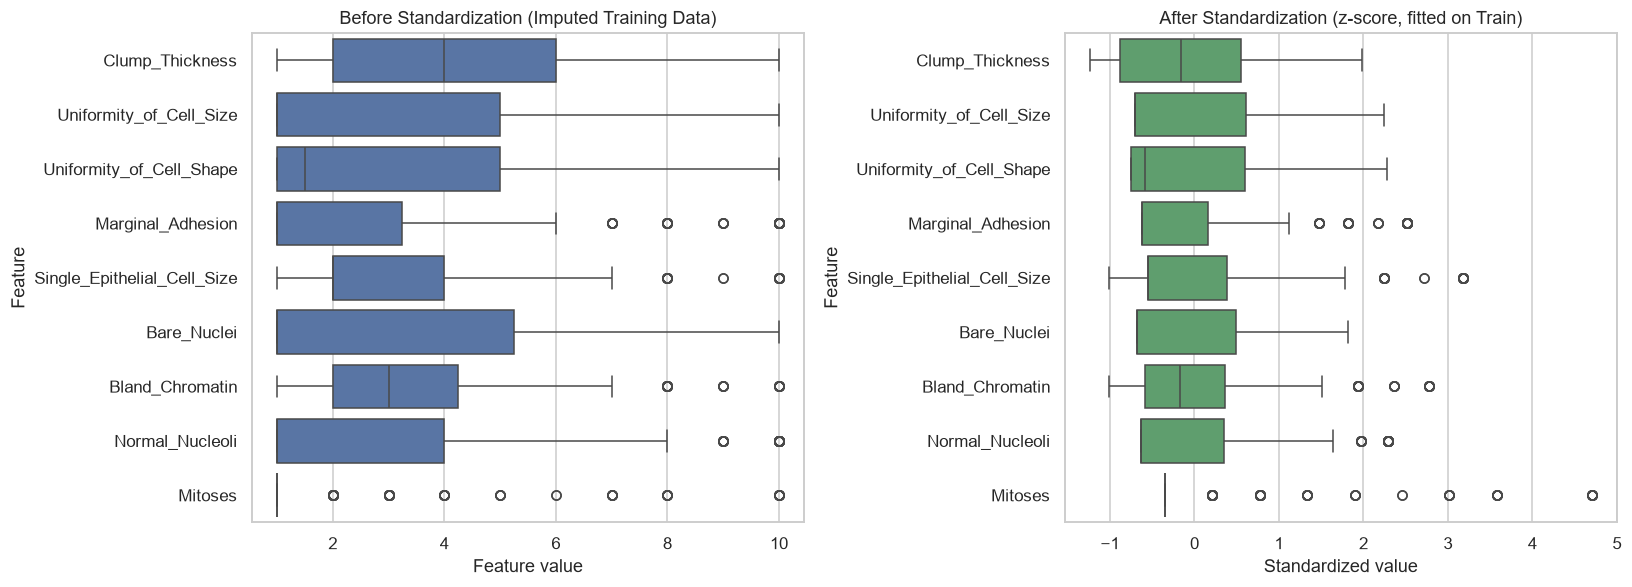

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=False)
sns.boxplot(data=X_train_imp, orient="h", color="#4C72B0", ax=axes[0])
axes[0].set_title("Before Standardization (Imputed Training Data)")
axes[0].set_xlabel("Feature value"); axes[0].set_ylabel("Feature")

sns.boxplot(data=X_train_scaled, orient="h", color="#55A868", ax=axes[1])
axes[1].set_title("After Standardization (z-score, fitted on Train)")
axes[1].set_xlabel("Standardized value"); axes[1].set_ylabel("Feature")
plt.tight_layout(); save_fig("06a_standardization_boxplots"); plt.show()

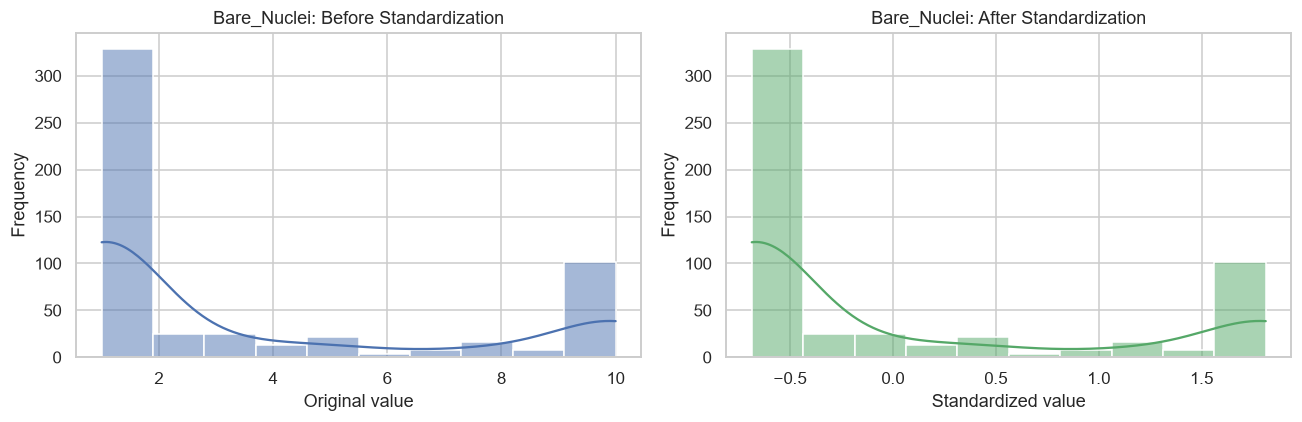

In [19]:
feat = "Bare_Nuclei"
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(X_train_imp[feat], bins=10, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title(f"{feat}: Before Standardization")
axes[0].set_xlabel("Original value"); axes[0].set_ylabel("Frequency")
sns.histplot(X_train_scaled[feat], bins=10, kde=True, color="#55A868", ax=axes[1])
axes[1].set_title(f"{feat}: After Standardization")
axes[1].set_xlabel("Standardized value"); axes[1].set_ylabel("Frequency")
plt.tight_layout(); save_fig("06b_standardization_histogram"); plt.show()

**Interpretation:** Before scaling, features have different means and spreads (e.g., `Mitoses` is concentrated near 1 while `Clump_Thickness` is spread over 1–10). After standardization every feature is centred at 0 with a standard deviation of 1. The **shape** of each distribution is unchanged (the histogram is only shifted/rescaled) — which is expected, because standardization is a linear transformation. This puts all features on equal footing for KNN (distance), SVM (kernel/margin) and ANN (gradient descent).

---
# Task 4: Model Implementation and Hyperparameter Tuning

Each model is wrapped in a `Pipeline` (imputer → [scaler] → classifier). `GridSearchCV` with **5-fold stratified cross-validation on the training set** searches the hyperparameter grid; the imputer/scaler are re-fitted inside every fold, so the validation fold never leaks into preprocessing.

**Tuning metric:** `F1-score` of the malignant class — it balances Precision and Recall of the positive class and is more informative than accuracy on a (moderately) imbalanced medical dataset. The test set is **not touched** in this task.

In [20]:
def make_pipe(model, scale):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", model))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "KNN": (make_pipe(KNeighborsClassifier(), scale=True),
            {"clf__n_neighbors": [3, 5, 7, 9, 11, 15],
             "clf__weights": ["uniform", "distance"],
             "clf__p": [1, 2]}),

    "Decision Tree": (make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False),
            {"clf__criterion": ["gini", "entropy"],
             "clf__max_depth": [2, 3, 4, 5, 6, 8, None],
             "clf__min_samples_split": [2, 5, 10],
             "clf__min_samples_leaf": [1, 2, 4]}),

    "Random Forest": (make_pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), scale=False),
            {"clf__n_estimators": [100, 200, 300],
             "clf__max_depth": [None, 5, 10],
             "clf__min_samples_leaf": [1, 2],
             "clf__max_features": ["sqrt", "log2"]}),

    "ANN (MLP)": (make_pipe(MLPClassifier(max_iter=2000, random_state=RANDOM_STATE), scale=True),
            {"clf__hidden_layer_sizes": [(16,), (32,), (32, 16)],
             "clf__activation": ["relu", "tanh"],
             "clf__alpha": [1e-4, 1e-3, 1e-2],
             "clf__learning_rate_init": [1e-3, 1e-2]}),

    "SVM": (make_pipe(SVC(probability=True, random_state=RANDOM_STATE), scale=True),
            {"clf__kernel": ["linear", "rbf"],
             "clf__C": [0.1, 1, 10, 100],
             "clf__gamma": ["scale", "auto"]}),
}

In [21]:
best_models, cv_summary = {}, []

for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)                       # TRAIN ONLY
    best_models[name] = gs.best_estimator_
    cv_summary.append({"Model": name,
                       "Best CV F1": round(gs.best_score_, 4),
                       "Best hyperparameters": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}})
    print(f"{name:14s} | best CV F1 = {gs.best_score_:.4f} | {gs.best_params_}")

cv_table = pd.DataFrame(cv_summary).set_index("Model")
cv_table

KNN            | best CV F1 = 0.9555 | {'clf__n_neighbors': 7, 'clf__p': 2, 'clf__weights': 'uniform'}
Decision Tree  | best CV F1 = 0.9297 | {'clf__criterion': 'gini', 'clf__max_depth': 4, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2}
Random Forest  | best CV F1 = 0.9512 | {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 300}
ANN (MLP)      | best CV F1 = 0.9530 | {'clf__activation': 'relu', 'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (32,), 'clf__learning_rate_init': 0.001}
SVM            | best CV F1 = 0.9503 | {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}


,Best CV F1,Best hyperparameters
Model,,
KNN,0.9555,"{'n_neighbors': 7, 'p': 2, 'weights': 'uniform'}"
Decision Tree,0.9297,"{'criterion': 'gini', 'max_depth': 4, 'min_sam..."
Random Forest,0.9512,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
ANN (MLP),0.9530,"{'activation': 'relu', 'alpha': 0.0001, 'hidde..."
SVM,0.9503,"{'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}"


### Brief description of the five algorithms
- **K-Nearest Neighbors (KNN):** classifies a sample by majority vote among its *k* closest training samples (distance in feature space). Needs scaling. Tuned: `k`, vote weighting, distance metric (Manhattan/Euclidean).
- **Decision Tree (DT):** learns a hierarchy of if/else splits on features that best separate the classes (Gini/entropy). Easy to interpret but prone to overfitting. Tuned: depth, minimum samples per split/leaf, criterion.
- **Random Forest (RF):** an ensemble of many decision trees trained on bootstrap samples with random feature subsets; predictions are averaged. Reduces variance/overfitting. Tuned: number of trees, depth, leaf size, `max_features`.
- **Artificial Neural Network (ANN / MLP):** layers of neurons with non-linear activations trained by back-propagation. Needs scaling. Tuned: hidden layer sizes, activation, L2 regularization (`alpha`), learning rate.
- **Support Vector Machine (SVM):** finds the maximum-margin separating boundary; the RBF kernel allows non-linear boundaries. Needs scaling. Tuned: kernel, `C` (margin softness), `gamma`.

---
# Task 5: Model Evaluation

**Evaluation uses the held-out test set — for the first and only time.** Malignant = positive class (`1`).

### Metric definitions
With TP = malignant correctly detected, TN = benign correctly detected, FP = benign wrongly flagged malignant, FN = malignant missed:

- **Accuracy** = (TP + TN) / total — overall share of correct predictions.
- **Precision** = TP / (TP + FP) — of the cases predicted malignant, how many truly are. Low precision → unnecessary biopsies/anxiety.
- **Recall (Sensitivity)** = TP / (TP + FN) — of all truly malignant cases, how many we catch. Low recall → **missed cancers** (the most dangerous error).
- **F1-score** = harmonic mean of Precision and Recall.
- **ROC-AUC** = probability that the model ranks a random malignant sample higher than a random benign one; threshold-independent (1.0 = perfect, 0.5 = random).

In [22]:
def get_scores(model, X):
    """Continuous score for the positive class (used for ROC-AUC)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

results, cms, roc_data = [], {}, {}

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_score = get_scores(model, X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1),
        "Recall": recall_score(y_test, y_pred, pos_label=1),
        "F1-score": f1_score(y_test, y_pred, pos_label=1),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    })
    cms[name] = confusion_matrix(y_test, y_pred, labels=[0, 1])
    roc_data[name] = roc_curve(y_test, y_score)

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.to_csv("results_table.csv")
print("Test-set size:", len(y_test), "| malignant cases:", int(y_test.sum()))
results_df.style.highlight_max(axis=0, color="#c6efce").format("{:.4f}")

Test-set size: 139 | malignant cases: 48


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN,0.9640,0.9778,0.9167,0.9462,0.9823
Decision Tree,0.9281,0.8958,0.8958,0.8958,0.9755
Random Forest,0.9568,0.9565,0.9167,0.9362,0.9938
ANN (MLP),0.9712,0.9583,0.9583,0.9583,0.9961
SVM,0.9640,0.9574,0.9375,0.9474,0.9966


### 5.1 Confusion matrices (one per model)

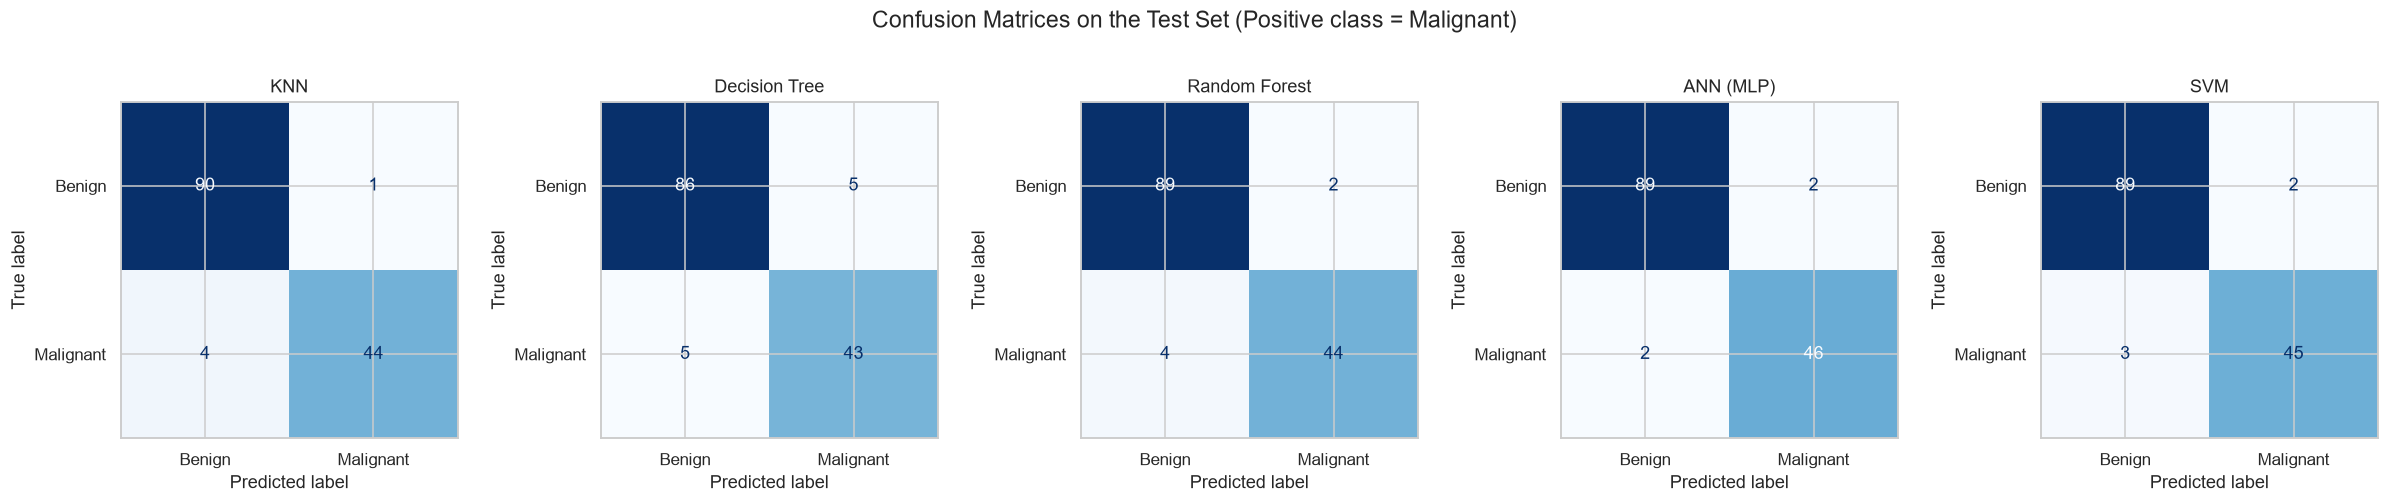

,TN,FP,FN,TP
KNN,90,1,4,44
Decision Tree,86,5,5,43
Random Forest,89,2,4,44
ANN (MLP),89,2,2,46
SVM,89,2,3,45


In [23]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
fig.suptitle("Confusion Matrices on the Test Set (Positive class = Malignant)", fontsize=15, y=1.05)
plt.tight_layout(); save_fig("07_confusion_matrices"); plt.show()

cm_table = pd.DataFrame({n: {"TN": c[0, 0], "FP": c[0, 1], "FN": c[1, 0], "TP": c[1, 1]} for n, c in cms.items()}).T
cm_table

**How to read them:** the bottom-left cell is **False Negatives** (malignant predicted as benign) — the most critical error in this medical context; the top-right cell is **False Positives** (benign flagged as malignant). Compare the `FN` column in the table above across models.

### 5.2 ROC curves

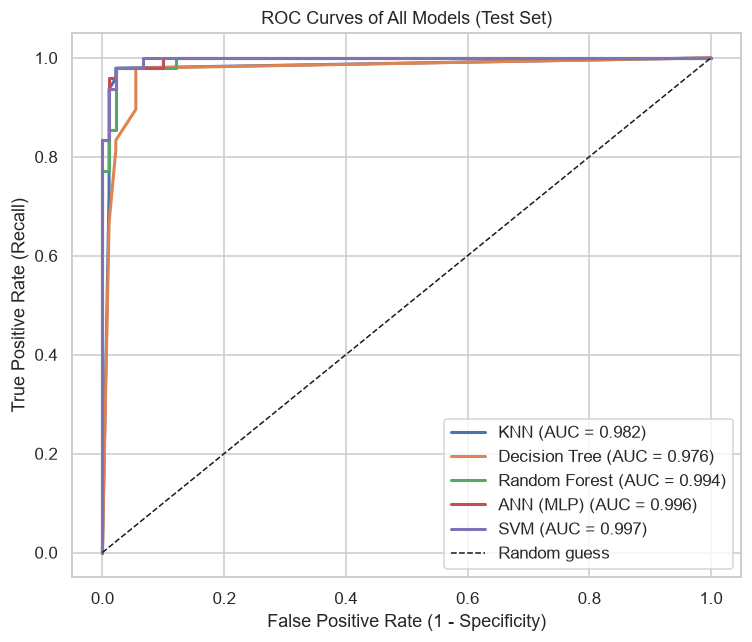

In [24]:
plt.figure(figsize=(7, 6))
for name, (fpr, tpr, _) in roc_data.items():
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {results_df.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
plt.title("ROC Curves of All Models (Test Set)")
plt.xlabel("False Positive Rate (1 - Specificity)"); plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right"); plt.tight_layout(); save_fig("08_roc_curves"); plt.show()

**Interpretation:** curves that hug the top-left corner indicate better separation between benign and malignant cases. On this dataset all models are expected to be very close to each other, so small AUC differences should be interpreted with caution given the small test set.

### 5.3 Comparison table and bar chart

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN,0.9640,0.9778,0.9167,0.9462,0.9823
Decision Tree,0.9281,0.8958,0.8958,0.8958,0.9755
Random Forest,0.9568,0.9565,0.9167,0.9362,0.9938
ANN (MLP),0.9712,0.9583,0.9583,0.9583,0.9961
SVM,0.9640,0.9574,0.9375,0.9474,0.9966


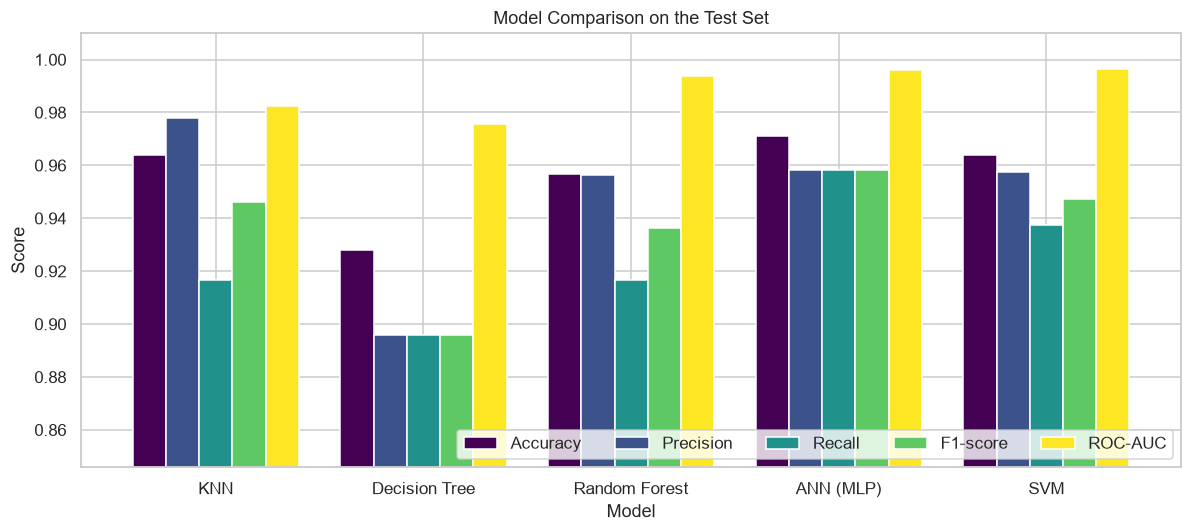

In [25]:
display(results_df)

ax = results_df.plot(kind="bar", figsize=(11, 5), width=0.8, colormap="viridis")
ax.set_title("Model Comparison on the Test Set")
ax.set_xlabel("Model"); ax.set_ylabel("Score")
ax.set_ylim(max(0, results_df.values.min() - 0.05), 1.01)
plt.xticks(rotation=0); plt.legend(loc="lower right", ncol=5)
plt.tight_layout(); save_fig("09_model_comparison"); plt.show()

### 5.4 Is the ranking reliable? Cross-validation check on the training set

The test set is small (~137 samples), so one or two predictions can change a ranking. As an additional robustness check we compare the tuned models using **repeated cross-validation on the training data** (not the test set). This helps avoid over-trusting a single split.

In [26]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name, model in best_models.items():
    cvres = cross_validate(model, X_train, y_train, cv=rcv, n_jobs=-1,
                           scoring={"recall": "recall", "f1": "f1", "roc_auc": "roc_auc"})
    rows.append({"Model": name,
                 "CV Recall (mean ± std)": f"{cvres['test_recall'].mean():.4f} ± {cvres['test_recall'].std():.4f}",
                 "CV F1 (mean ± std)": f"{cvres['test_f1'].mean():.4f} ± {cvres['test_f1'].std():.4f}",
                 "CV ROC-AUC (mean ± std)": f"{cvres['test_roc_auc'].mean():.4f} ± {cvres['test_roc_auc'].std():.4f}"})
pd.DataFrame(rows).set_index("Model")

,CV Recall (mean ± std),CV F1 (mean ± std),CV ROC-AUC (mean ± std)
Model,,,
KNN,0.9561 ± 0.0314,0.9503 ± 0.0256,0.9888 ± 0.0108
Decision Tree,0.9228 ± 0.0548,0.9160 ± 0.0318,0.9592 ± 0.0222
Random Forest,0.9632 ± 0.0285,0.9498 ± 0.0228,0.9909 ± 0.0058
ANN (MLP),0.9632 ± 0.0316,0.9523 ± 0.0252,0.9927 ± 0.0056
SVM,0.9579 ± 0.0330,0.9520 ± 0.0267,0.9941 ± 0.0042


### 5.5 Selecting the best model

In [27]:
print("Best model per metric (test set):")
for m in results_df.columns:
    best = results_df[m].max()
    winners = ", ".join(results_df.index[results_df[m] == best])
    print(f"  {m:10s}: {winners}  ({best:.4f})")

# Overall ranking: priority Recall (avoid missed cancers) -> F1 -> ROC-AUC -> Accuracy
ranking = results_df.sort_values(["Recall", "F1-score", "ROC-AUC", "Accuracy"], ascending=False)
print("\nOverall ranking (priority: Recall > F1 > ROC-AUC > Accuracy):")
display(ranking)
print("Selected model:", ranking.index[0])

Best model per metric (test set):
  Accuracy  : ANN (MLP)  (0.9712)
  Precision : KNN  (0.9778)
  Recall    : ANN (MLP)  (0.9583)
  F1-score  : ANN (MLP)  (0.9583)
  ROC-AUC   : SVM  (0.9966)

Overall ranking (priority: Recall > F1 > ROC-AUC > Accuracy):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
ANN (MLP),0.9712,0.9583,0.9583,0.9583,0.9961
SVM,0.9640,0.9574,0.9375,0.9474,0.9966
KNN,0.9640,0.9778,0.9167,0.9462,0.9823
Random Forest,0.9568,0.9565,0.9167,0.9362,0.9938
Decision Tree,0.9281,0.8958,0.8958,0.8958,0.9755


Selected model: ANN (MLP)



### Interpretation and justification of the best model

> ✍️ **Complete this cell after running the notebook** using your actual numbers. Suggested structure:
>
> 1. **Results summary:** Which model has the highest Accuracy, F1 and ROC-AUC? (quote the numbers from the comparison table).
> 2. **Error analysis (confusion matrices):** How many malignant cases did each model miss (FN)? How many false alarms (FP)?
> 3. **Why Recall matters most here:** missing a malignant tumor (False Negative) can delay treatment and is far more costly than a false alarm, which is resolved with further tests. So among models with similar F1/AUC, the one with the **highest Recall / fewest FN** is preferred.
> 4. **Selected model and justification:** state the model chosen by the ranking above, and support it with Recall, F1, ROC-AUC and the repeated-CV table (stability: low std).
> 5. **Caveat:** differences between top models are often 1–2 samples on a ~137-sample test set, so they may not be statistically significant; simpler/more interpretable models can be preferred when performance is tied.

In [28]:
best_name = ranking.index[0]
print(f"Detailed classification report for the selected model: {best_name}\n")
print(classification_report(y_test, best_models[best_name].predict(X_test),
                            target_names=["Benign (0)", "Malignant (1)"], digits=4))

Detailed classification report for the selected model: ANN (MLP)

               precision    recall  f1-score   support

   Benign (0)     0.9780    0.9780    0.9780        91
Malignant (1)     0.9583    0.9583    0.9583        48

     accuracy                         0.9712       139
    macro avg     0.9682    0.9682    0.9682       139
 weighted avg     0.9712    0.9712    0.9712       139

